# Analyse de la concentration de CO2 dans l'atmosphère depuis 1958

Ce projet analyse l'évolution de la concentration de CO2 dans l'atmosphère et propose une modélisation de son évolution. Le jeu de données couvre la période de 1958 à la semaine 42 de l'année 2026, avec une dernière observation enregistrée le 17 octobre 2026. Les observations sont hebdomadaires et proviennent du site de l'Université de Californie à San Diego (UC San Diego) : [données](https://scrippsco2.ucsd.edu/data/atmospheric-co2-data/sampling-station-records/mauna-loa-observatory-hawaii/).

In [1]:
# Importations 
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from urllib.error import HTTPError, URLError

from urllib.request import Request, urlopen

## bibliothèques pour gérer les timeseries
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pmdarima as pm
from joblib import Parallel, delayed
import joblib

In [2]:
# configurations générales
PATH = os.getcwd()
URL = "https://keelinglabsites.ucsd.edu/websitedataco2/weekly_in_situ_co2_mlo.csv"


In [3]:

def extraire_donnees_weekly(url: str, chemin_fichier: str) -> Path:

    """Telecharge un fichier CSV CO2 hebdomadaire depuis son URL directe."""

    if not isinstance(url, str) or not url.strip():
        raise ValueError("L'URL doit etre une chaine non vide.")

    if not isinstance(chemin_fichier, str) or not chemin_fichier.strip():
        raise ValueError("Le chemin du fichier doit etre une chaine non vide.")

    try:
        request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urlopen(request) as response:
            contenu = response.read()
    except (HTTPError, URLError) as exc:
        raise Exception(f"Impossible de telecharger le fichier CSV {url!r}: {exc}") from exc

    destination = Path(chemin_fichier)
    destination.parent.mkdir(parents=True, exist_ok=True)

    try:
        destination.write_bytes(contenu)

    except OSError as exc:
        raise Exception(f"Impossible d'enregistrer le fichier {destination!s}.") from exc

    return destination


## Télechargement du fichier CSV CO2 hebdomadaire depuis son URL directe
file_path = os.path.join(PATH, "co2_weekly_mlo.csv")
if os.path.exists(file_path):
    fichier_weekly = Path(file_path)
else:
    fichier_weekly = extraire_donnees_weekly(URL, os.path.join(PATH, "co2_weekly_mlo.csv"))


fichier_weekly


WindowsPath('d:/Junior/Projets/Rechauffement_climatique/co2_weekly_mlo.csv')

In [4]:
data_weekly = pd.read_csv(fichier_weekly, comment='"', header=None, names=["date", "co2"])
print(data_weekly.head())
print('================================Nature des données================================')
data_weekly.info()

         date     co2
0  1958-03-29  316.19
1  1958-04-05  317.31
2  1958-04-12  317.69
3  1958-04-19  317.58
4  1958-04-26  316.48
================================Nature des données================================
<class 'pandas.DataFrame'>
RangeIndex: 3502 entries, 0 to 3501
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    3502 non-null   str    
 1   co2     3502 non-null   float64
dtypes: float64(1), str(1)
memory usage: 89.0 KB


On remarque que la colonne "date" de notre jeu de données importé est compris comme un objet de type chaîne de caractère. Or, pour nos analyses, nous avons besoin qu'elle soit de type datetime. Nous allons alors la convertir

In [5]:
## Conversion de la colonne "date" en type datetime
data_weekly['date'] = pd.to_datetime(data_weekly['date'], format='%Y-%m-%d')
data_weekly.info()

<class 'pandas.DataFrame'>
RangeIndex: 3502 entries, 0 to 3501
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    3502 non-null   datetime64[us]
 1   co2     3502 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 54.8 KB


Les données ne présentent pas de valeurs manquantes. Nous allons malgré tout les vérifier.

In [6]:
data_weekly.isnull().sum()

date    0
co2     0
dtype: int64

Après la préparation et le chargement des données, nous allons passer à leur exploration

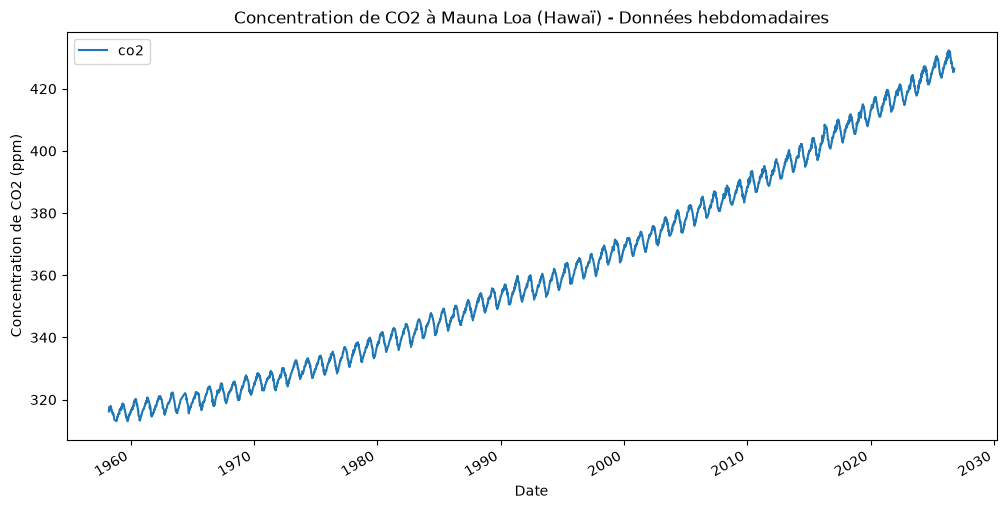

In [7]:
fig,ax = plt.subplots(figsize=(12,6))
data_weekly.plot(x='date', y='co2', ax=ax)
plt.title('Concentration de CO2 à Mauna Loa (Hawaï) - Données hebdomadaires')
plt.xlabel('Date')
plt.ylabel('Concentration de CO2 (ppm)')
plt.show()

L'analyse du graphique met en évidence une tendance à la hausse ainsi qu'une saisonnalité a priori additive de la concentration de CO2 dans l'atmosphère depuis 1960. La série observée n'est donc pas stationnaire ; il est nécessaire de la stationnariser avant de poursuivre la modélisation. Cette transformation constitue une étape essentielle pour identifier un modèle adapté à la série.

## Identification du modèle

Nous commencerons par identifier la période de la saisonnalité, puis nous stationnariserons la série. Cette étape permettra de déterminer l'ordre d'intégration des composantes non saisonnière et saisonnière. Nous identifierons ensuite les ordres éventuels des composantes autorégressive (AR) et moyenne mobile (MA) à l'aide des fonctions d'autocorrélation ACF et PACF.

Pour identifier la période saisonnière, nous retirerons d'abord la tendance de la série, puis nous examinerons sa fonction d'autocorrélation (ACF). Nous partirons de l'hypothèse d'une saisonnalité annuelle, soit une période de 52 semaines.

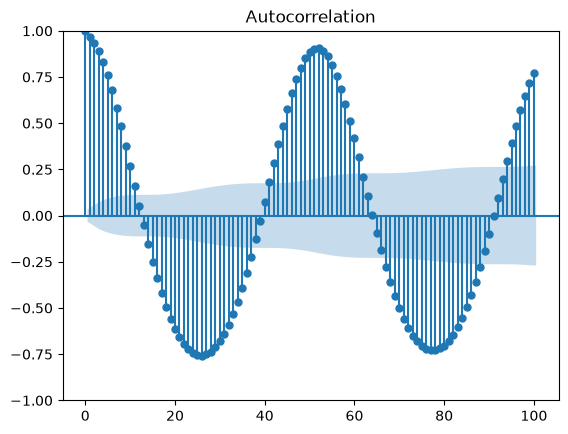

In [8]:
# detrending the data to remove the seasonal component
data_weekly['co2_detrended'] = data_weekly['co2'] - data_weekly['co2'].rolling(window=52).mean()
plot_acf(data_weekly['co2_detrended'].dropna(), lags=100)
plt.show()

Le graphique ACF met en évidence une saisonnalité de période 52 semaines, ce qui confirme notre hypothèse d'une saisonnalité annuelle. Avant de stationnariser la série, nous vérifierons sa non-stationnarité à l'aide du test de Dickey-Fuller. Nous procéderons ensuite à sa désaisonnalisation, puis nous vérifierons à nouveau si la série est devenue stationnaire.

In [9]:
adfuller_result = adfuller(data_weekly['co2'],result_object=False)
print(f"p-value: {adfuller_result[1]}")

p-value: 0.9983065530168713


La p-value du test est plus grand que 0.05 alors on ne peut rejecter l'hypothèse nul de l'existence de racine unitaire pour la série. Par conséquent la série n'est pas stationnaire. Effectuons une différenciation d'ordre 52 afin de désaisonnaliser la série.

In [6]:
co2_weekly = data_weekly.set_index('date')['co2']
co2_weekly = co2_weekly.asfreq('W-SAT')

co2_weekly_seasonal = co2_weekly.diff(52).dropna()
adfuller_result_diff = adfuller(co2_weekly_seasonal, result_object=False)
print(f"p-value after differencing: {adfuller_result_diff[1]}")

p-value after differencing: 3.4403611703061436e-05


Après désaisonnalisation de la série, on observe qu'elle devient stationnaire. Une répresentation des fonctions ACF et PACF nous permettra d'identifier les ordres p et q respectifs des composantes AR et MA.

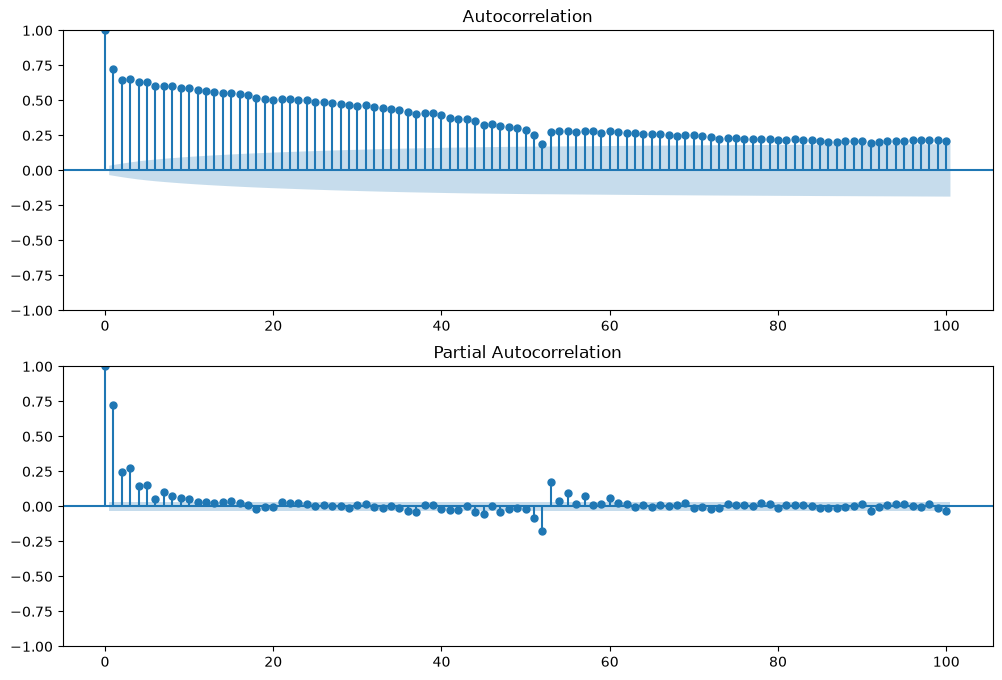

In [11]:
fig,(ax1,ax2) = plt.subplots(2,1,figsize=(12,8))
plot_acf(co2_weekly_seasonal, lags=100, ax=ax1)
plot_pacf(co2_weekly_seasonal, lags=100, ax=ax2)
plt.show()

Le graphique de la fonction ACF suggère de différencier à nouveau la série; ce que nous faisons dans la suite.

p-value after second differencing: 0.0


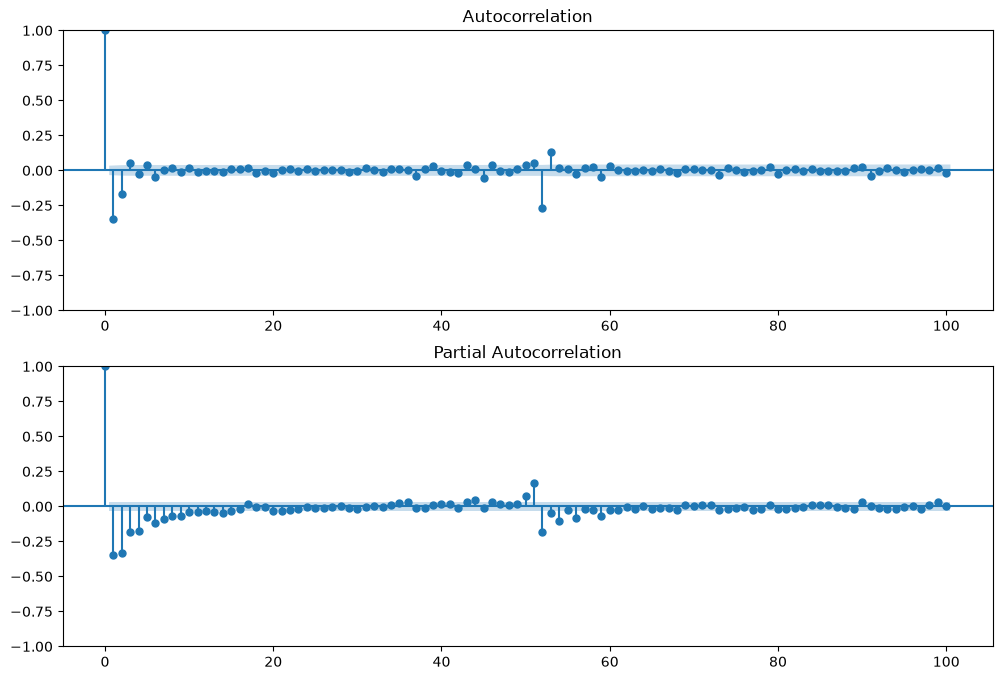

In [12]:
co2_weekly_seasonal_diff = co2_weekly_seasonal.diff().dropna()
print(f"p-value after second differencing: {adfuller(co2_weekly_seasonal_diff, result_object=False)[1]}")
fig,(ax1,ax2) = plt.subplots(2,1,figsize=(12,8))
plot_acf(co2_weekly_seasonal_diff, lags=100, ax=ax1)
plot_pacf(co2_weekly_seasonal_diff, lags=100, ax=ax2)
plt.show()

La seconde différenciation suggère d'envisager un terme AR(2) et un terme MA(4) pour la composante non saisonnière, ainsi que des termes AR et MA non nuls pour la composante saisonnière. Afin de retenir une spécification adaptée, nous effectuerons une sélection automatique des modèles selon le critère d'AIC, privilégié ici parce que notre objectif est d'obtenir de bonnes performances prédictives.

In [13]:
# order_aic_bic=[]
# # Loop over p values from 0-2
# for p in range(3):
#     for q in range(4):
#         for p_s in range(3):
#             for q_s in range(3):
#                 try:
#                     model = SARIMAX(co2_weekly, order=(p+1,1,q+1), seasonal_order=(p_s,1,q_s,52))
#                     results = model.fit()
#                     # Append order and results tuple
#                     order_aic_bic.append((p,q,p_s,q_s,results.aic,results.bic))
#                 except:
#                     order_aic_bic.append((p,q,p_s,q_s,None,None))


# results_df = pd.DataFrame(order_aic_bic)
# print(results_df)

# Fonction qui teste une combinaison
def fit_sarimax(p, q, p_s, q_s, series):
    try:
        model = SARIMAX(
            series,
            order=(p+1, 1, q+1),
            seasonal_order=(p_s, 1, q_s, 52),
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        results = model.fit(maxiter=500, disp=False)
        return (p, q, p_s, q_s, results.aic, results.bic)
    except Exception:
        return (p, q, p_s, q_s, None, None)

# Lancer en parallèle sur tous les cœurs disponibles
order_aic_bic = Parallel(n_jobs=-1, verbose=10)(
    delayed(fit_sarimax)(p, q, p_s, q_s, co2_weekly)
    for p in range(3)
    for q in range(4)
    for p_s in range(3)
    for q_s in range(3)
)

# Résultats en DataFrame
results_df = pd.DataFrame(order_aic_bic, 
                          columns=["p","q","P","Q","AIC","BIC"])
print(results_df)

                            

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:   15.3s
[Parallel(n_jobs=-1)]: Done   8 tasks      | elapsed:  5.1min
[Parallel(n_jobs=-1)]: Done  17 tasks      | elapsed: 20.7min
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed: 88.2min
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed: 144.6min
[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed: 236.6min
[Parallel(n_jobs=-1)]: Done  61 tasks      | elapsed: 713.5min
[Parallel(n_jobs=-1)]: Done  74 tasks      | elapsed: 762.4min
[Parallel(n_jobs=-1)]: Done  96 out of 108 | elapsed: 1172.6min remaining: 146.6min


     p  q  P  Q          AIC          BIC
0    0  0  0  0  6477.444444  6495.880223
1    0  0  0  1  4884.207838  4908.728074
2    0  0  0  2  4818.443612  4849.016732
3    0  0  1  0  5540.291331  5564.812745
4    0  0  1  1  4877.440178  4908.090473
..  .. .. .. ..          ...          ...
103  2  3  1  1  4762.087552  4823.379302
104  2  3  1  2  4625.953420  4693.204407
105  2  3  2  0  4879.303783  4940.447031
106  2  3  2  1  4699.697959  4766.955531
107  2  3  2  2  4698.197164  4771.561877

[108 rows x 6 columns]


[Parallel(n_jobs=-1)]: Done 108 out of 108 | elapsed: 1379.0min finished


Le modèle retenu est celui qui minimise le critère d'AIC. Nous privilégions l'AIC au BIC, car notre objectif principal est de sélectionner le modèle offrant les meilleures performances prédictives.

In [ ]:
best_model_order = results_df.loc[results_df['AIC'].idxmin()]
print(f"Best model order based on AIC: {best_model_order}")

Best model order based on AIC: p         2.000000
q         3.000000
P         1.000000
Q         2.000000
AIC    4625.953420
BIC    4693.204407
Name: 104, dtype: float64


Ainsi, le modèle retenu est un SARIMA(3,1,3)(1,1,2,52). Nous allons maintenant estimer ses paramètres, puis évaluer la qualité de son ajustement à l'aide d'un diagnostic des résidus.

In [7]:
model = SARIMAX(co2_weekly, order=(3, 1, 3),
                seasonal_order=(1, 1, 2, 52))
res = model.fit()
print(res.summary())

d:\Junior\Projets\Rechauffement_climatique\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


                                        SARIMAX Results                                        
Dep. Variable:                                     co2   No. Observations:                 3578
Model:             SARIMAX(3, 1, 3)x(1, 1, [1, 2], 52)   Log Likelihood               -2138.635
Date:                                 Thu, 26 Nov 2026   AIC                           4297.270
Time:                                         20:23:15   BIC                           4358.946
Sample:                                     03-29-1958   HQIC                          4319.273
                                          - 10-17-2026                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0447      0.107      0.416      0.677      -0.166       0

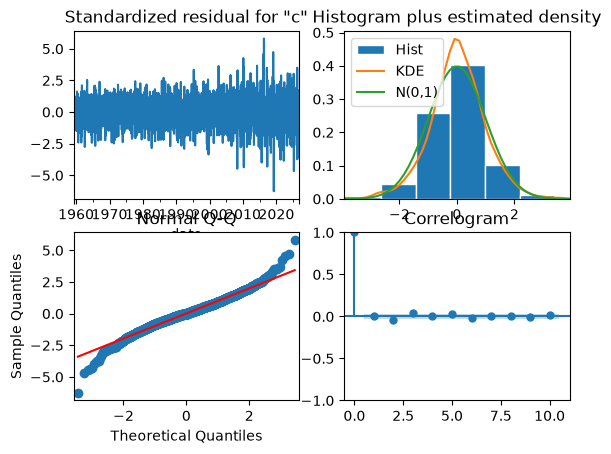

In [8]:
_ = res.plot_diagnostics()

Le diagnostic indique que les résidus se comportent comme un bruit blanc, ce que confirme le test de Ljung-Box présenté dans le résumé du modèle. En revanche, leur distribution ne semble pas normale : la loi normale standard s'ajuste imparfaitement à l'histogramme et les quantiles théoriques ne coïncident pas parfaitement avec les quantiles empiriques sur le QQ-plot. Le test de Jarque-Bera conduit également à rejeter l'hypothèse nulle de normalité. Malgré cette non-normalité, nous conservons le modèle, car ses résidus satisfont le critère d'absence d'autocorrélation. Nous pouvons maintenant passer aux prédictions.

## Prédiction 

Nous allons effectuer dans un premier temps des prédiction in sample puis out-sample sur un horizon de 1 an

<Axes: xlabel='date'>

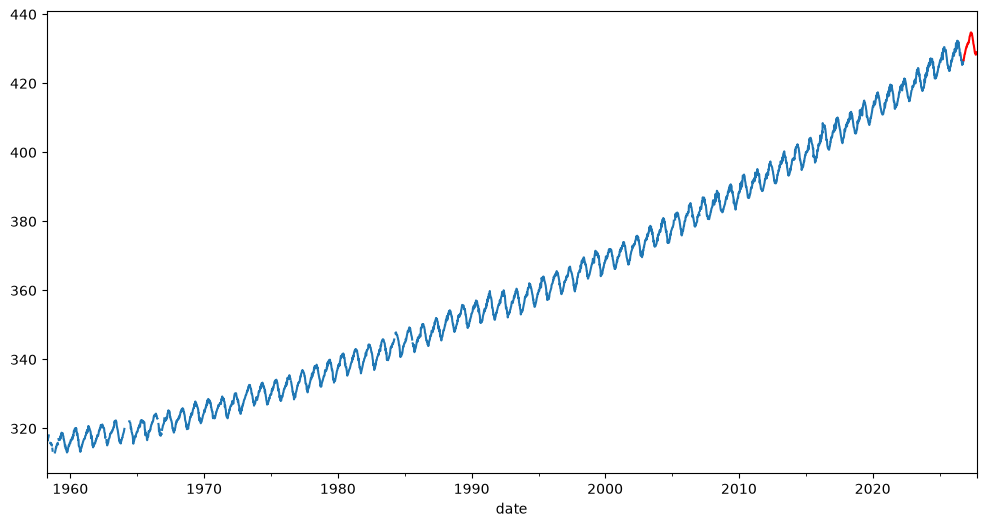

In [9]:
pred = res.get_forecast(steps=52)
forecast = pred.predicted_mean
conf_int = pred.conf_int()

fig, ax = plt.subplots(figsize=(12,6))

co2_weekly.plot(ax=ax, label="Observé")
forecast.plot(ax=ax, color="red", label="Prévision")

In [19]:
print(conf_int)

             lower co2   upper co2
2026-10-24  425.901693  427.570350
2026-10-31  426.296841  428.108665
2026-11-07  426.635409  428.511883
2026-11-14  427.225979  429.150678
2026-11-21  427.528311  429.493738
2026-11-28  427.542852  429.552173
2026-12-05  428.009287  430.051323
2026-12-12  428.376341  430.441713
2026-12-19  428.711906  430.805289
2026-12-26  429.047704  431.167643
2027-01-02  429.111662  431.256403
2027-01-09  429.616854  431.790085
2027-01-16  429.525017  431.716244
2027-01-23  429.665035  431.884224
2027-01-30  430.114323  432.348593
2027-02-06  430.281833  432.536766
2027-02-13  430.190388  432.465169
2027-02-20  430.587877  432.882298
2027-02-27  430.656470  432.969789
2027-03-06  430.506746  432.838955
2027-03-13  430.730264  433.080789
2027-03-20  431.258030  433.626843
2027-03-27  431.550861  433.937460
2027-04-03  432.214126  434.618528
2027-04-10  432.521872  434.943624
2027-04-17  432.549671  434.988823
2027-04-24  432.968506  435.424650
2027-05-01  433.2228

## Sauvegarde

Afin de permettre la réutiisation du modèle, nous allons enregistrer ses paramètres. De même pour permettre les prédictions futures sans nécessiter de recharger le modèle qui est volumineux en mémoire, nous allons enregistrer aussi les prévisions sur une horizon de 10 ans

In [10]:
filepath = os.path.join(PATH, "future_forecasts.pkl")
pred = res.get_forecast(steps=520)  # 10 ans

forecast_df = pd.DataFrame({
    "date": pred.predicted_mean.index,
    "forecast": pred.predicted_mean.values,
    "lower": pred.conf_int().iloc[:, 0].values,
    "upper": pred.conf_int().iloc[:, 1].values
})

try:
    joblib.dump(forecast_df, filepath)
except Exception as e:
    print(f"Erreur lors de l'enregistrement du fichier {filepath}: {e}")

In [25]:
filepath = os.path.join(PATH, "co2_model_light.pkl")

try:
    artifact = {
    "params": res.params,
    "order": res.model.order,
    "seasonal_order": res.model.seasonal_order
    }
    joblib.dump(artifact, filepath)
    print(f"Modèle sauvegardé avec succès à l'adresse {filepath}")
except Exception as e:
    raise(f"Savegarde non réussi {e}")


Modèle sauvegardé avec succès à l'adresse d:\Junior\Projets\Rechauffement_climatique\co2_model_light.pkl
